# Jour 2 — Dissimilarités et méthodes de partitionnement

**Projet final « Apprentissage non supervisé » — Segmentation de clientèle bancaire**

**Objectifs du jour (Chapitres 2 et 3.1)**

| Partie | Contenu |
|---|---|
| A | Matrices de dissimilarité : euclidienne, Manhattan, Gower, Hamming, Jaccard ; effet de la standardisation |
| B | K-means + méthode du coude |
| C | K-medoids sur la matrice de Gower |
| D | K-prototypes sur données mixtes |
| E | Modèle de mélange gaussien (GMM) + BIC / AIC |
| F | Tableau comparatif des méthodes |

In [1]:
# Mise en forme : toutes les bordures sur tous les tableaux du notebook
from IPython.display import HTML, display
display(HTML("<style>table, th, td {border: 1px solid #333 !important; border-collapse: collapse !important;} th, td {padding: 4px 8px !important;}</style>"))

In [2]:
import sys, time, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import pdist, squareform
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             adjusted_rand_score, pairwise_distances)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from kmodes.kprototypes import KPrototypes

from src.config import SEED, FIG, TAB, LAB, OUT, GOWER_CACHE
from src import preprocessing as pp
from src.clustering_utils import gower_matrix, kmedoids, knee_point

np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

# Tout le Jour 1 en une ligne
d = pp.prepare_all()
X_a, X_mixed, y = d["X_a"], d["X_mixed"], d["y"]
X_a_full = d["X_a_full"]
n = len(X_a)
print("Échantillon :", X_a.shape, "| Population :", X_a_full.shape)

Échantillon : (4000, 37) | Population : (41176, 37)


# Partie A — Mesures de dissimilarité

Une méthode de clustering regroupe les individus « proches ». Tout dépend donc de la définition de la proximité. Rappel des formules, pour deux clients $x$ et $x'$ décrits par $p$ variables :

| Distance | Formule | Type de variables |
|---|---|---|
| Euclidienne | $d(x,x') = \sqrt{\sum_j (x_j - x'_j)^2}$ | numériques |
| Manhattan | $d(x,x') = \sum_j \lvert x_j - x'_j\rvert$ | numériques (moins sensible aux extrêmes) |
| Hamming | proportion de variables où $x_j \neq x'_j$ | binaires **symétriques** |
| Jaccard | $1 - \dfrac{\text{nb de « oui » communs}}{\text{nb de « oui » chez l'un ou l'autre}}$ | binaires **asymétriques** |
| Gower | $d(x,x') = \dfrac{1}{p}\sum_j d_j(x_j,x'_j)$ avec $d_j = \dfrac{\lvert x_j-x'_j\rvert}{\text{étendue}_j}$ (numérique) ou $\mathbb{1}[x_j\neq x'_j]$ (catégorielle) | **mixtes** |

## A.1 Euclidienne et Manhattan : effet de la standardisation
On calcule les deux distances sur les données one-hot, **sans** puis **avec** standardisation des variables numériques.

In [3]:
X_raw, _ = pp.encode(X_mixed, standardize=False)   # one-hot, numériques NON standardisées

D_euc_raw = pairwise_distances(X_raw, metric="euclidean")
D_man_raw = pairwise_distances(X_raw, metric="manhattan")
D_euc = pairwise_distances(X_a, metric="euclidean")
D_man = pairwise_distances(X_a, metric="manhattan")
print("Taille d'une matrice de dissimilarité :", D_euc.shape, f"({D_euc.nbytes / 1e6:.0f} Mo)")

Taille d'une matrice de dissimilarité : (4000, 4000) (128 Mo)


**Qui pèse dans la distance ?** La distance euclidienne au carré est une somme de termes, un par variable. En moyenne, le poids d'une variable est proportionnel à sa **variance**. On regarde donc la part de chaque variable dans la variance totale.

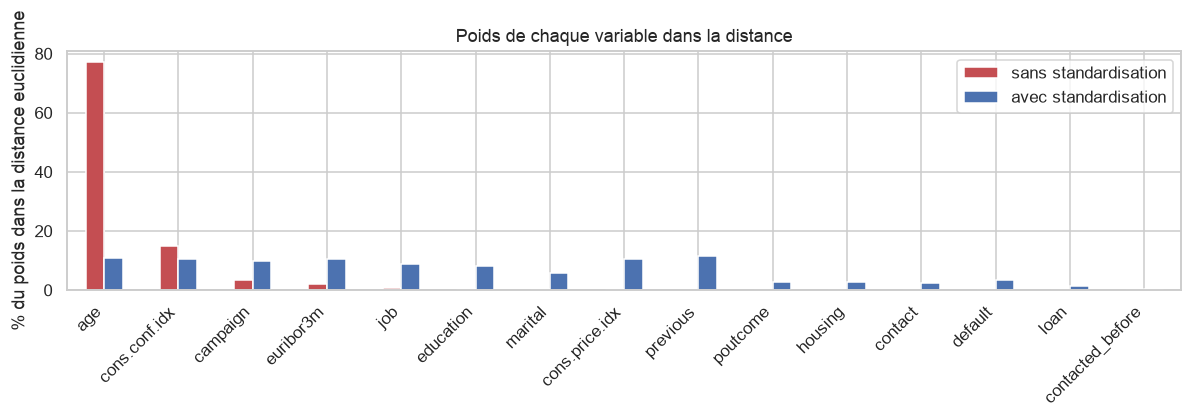

,sans standardisation,avec standardisation
age,77.0,10.9
cons.conf.idx,14.9,10.6
campaign,3.4,9.8
euribor3m,2.1,10.5
job,0.6,8.9
education,0.5,8.3
marital,0.4,5.7
cons.price.idx,0.2,10.7


In [4]:
def weight_by_variable(X):
    """Part (%) de chaque variable d'origine dans la variance totale."""
    var = X.var()
    groups = {c: (c if c in pp.ACTIVE_NUM else c.rsplit("_", 1)[0] if c.startswith("contacted") else c.split("_")[0])
              for c in X.columns}
    return (100 * var.groupby(groups).sum() / var.sum()).sort_values(ascending=False)

w = pd.DataFrame({"sans standardisation": weight_by_variable(X_raw),
                  "avec standardisation": weight_by_variable(X_a)}).fillna(0)
w = w.sort_values("sans standardisation", ascending=False)
ax = w.plot.bar(figsize=(11, 3.8), color=["#C44E52", "#4C72B0"])
ax.set_ylabel("% du poids dans la distance euclidienne"); ax.set_title("Poids de chaque variable dans la distance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout(); plt.savefig(FIG / "02_poids_variables.png", bbox_inches="tight"); plt.show()
w.round(1).head(8)

In [5]:
# Les voisinages changent-ils ? On compare les 10 plus proches voisins de chaque client.
def knn_sets(D, k=10):
    return np.argsort(D, axis=1)[:, 1:k + 1]

def overlap(Da, Db, k=10):
    A, B = knn_sets(Da, k), knn_sets(Db, k)
    return np.mean([len(set(a) & set(b)) / k for a, b in zip(A, B)])

print(f"Voisins communs (10-NN) euclidienne brute vs standardisée : {overlap(D_euc_raw, D_euc):.1%}")
print(f"Voisins communs (10-NN) Manhattan  brute vs standardisée : {overlap(D_man_raw, D_man):.1%}")
print(f"Voisins communs (10-NN) euclidienne vs Manhattan (standardisées) : {overlap(D_euc, D_man):.1%}")

Voisins communs (10-NN) euclidienne brute vs standardisée : 23.1%


Voisins communs (10-NN) Manhattan  brute vs standardisée : 37.2%


Voisins communs (10-NN) euclidienne vs Manhattan (standardisées) : 82.7%


**Lecture :**
- **Sans standardisation**, l'`age` écrase tout : il porte à lui seul 77 % de la distance, simplement parce qu'il est exprimé en dizaines d'unités. Deux clients seraient jugés « proches » dès qu'ils ont le même âge, quels que soient leur métier ou leur historique.
- **Avec standardisation**, les six variables numériques ont le même poids et les variables catégorielles retrouvent une influence.
- Les voisinages sont profondément modifiés : seuls 23 % des 10 plus proches voisins d'un client restent les mêmes. La standardisation n'est donc pas un détail technique, elle **change les groupes**.
- Euclidienne et Manhattan (standardisées) donnent des voisinages proches : le choix entre les deux a peu d'effet ici.

**Limite qui reste** : même standardisée, la représentation (a) met sur la même échelle un écart-type d'âge et un changement de modalité 0/1. Ce mélange est arbitraire. C'est ce que corrige la distance de Gower.

## A.2 Distance de Gower (données mixtes)
Gower traite chaque variable selon sa nature, ramène chaque contribution dans $[0, 1]$, puis fait la moyenne. Chaque variable compte donc pour $1/15$, qu'elle soit numérique ou catégorielle.

In [6]:
t0 = time.perf_counter()
D_gow = gower_matrix(X_mixed, cache=GOWER_CACHE)
print(f"Matrice de Gower : {D_gow.shape}, calculée ou relue en {time.perf_counter() - t0:.1f} s")
print(f"min = {D_gow.min():.3f} | moyenne = {D_gow.mean():.3f} | max = {D_gow.max():.3f}")

Matrice de Gower : (4000, 4000), calculée ou relue en 11.0 s
min = 0.000 | moyenne = 0.349 | max = 0.873


In [7]:
# Illustration : le couple de clients le plus proche et le plus éloigné au sens de Gower
iu = np.triu_indices(n, k=1)
g = D_gow[iu]
i_far, j_far = iu[0][g.argmax()], iu[1][g.argmax()]
pos = np.where(g > 0)[0]
i_near, j_near = iu[0][pos[g[pos].argmin()]], iu[1][pos[g[pos].argmin()]]
print(f"Couple le plus PROCHE (Gower = {D_gow[i_near, j_near]:.4f})")
display(X_mixed.iloc[[i_near, j_near]])
print(f"Couple le plus ÉLOIGNÉ (Gower = {D_gow[i_far, j_far]:.3f})")
display(X_mixed.iloc[[i_far, j_far]])

Couple le plus PROCHE (Gower = 0.0000)


,age,campaign,previous,cons.price.idx,cons.conf.idx,euribor3m,job,marital,education,default,housing,loan,contact,poutcome,contacted_before
599,34,1,0,93.994,-36.4,4.857,services,married,high.school,no,no,no,telephone,nonexistent,no
4713,34,1,0,93.994,-36.4,4.858,services,married,high.school,no,no,no,telephone,nonexistent,no


Couple le plus ÉLOIGNÉ (Gower = 0.873)


,age,campaign,previous,cons.price.idx,cons.conf.idx,euribor3m,job,marital,education,default,housing,loan,contact,poutcome,contacted_before
9954,38,9,0,94.465,-41.8,4.959,admin.,single,university.degree,no,no,yes,telephone,nonexistent,no
38440,98,1,2,92.431,-26.9,0.730,retired,married,basic.4y,unknown,yes,no,cellular,success,yes


La distance se lit directement : le couple le plus proche ne diffère que par un détail numérique ; le couple le plus éloigné diffère sur presque toutes les variables.

## A.3 Hamming et Jaccard (variables binaires)
On isole le bloc des variables binaires, codées en « présence d'une caractéristique ».

In [8]:
B = pd.DataFrame({
    "pret_immobilier":   X_mixed["housing"] == "yes",
    "pret_personnel":    X_mixed["loan"] == "yes",
    "contact_mobile":    X_mixed["contact"] == "cellular",
    "deja_contacte":     X_mixed["contacted_before"] == "yes",
    "defaut_inconnu":    X_mixed["default"] != "no",
    "succes_precedent":  X_mixed["poutcome"] == "success",
})
print("Fréquence de chaque caractéristique (% de « oui ») :")
print((100 * B.mean()).round(1).to_string())

D_ham = squareform(pdist(B.values, metric="hamming"))
D_jac = squareform(pdist(B.values, metric="jaccard"))

Fréquence de chaque caractéristique (% de « oui ») :
pret_immobilier     56.2
pret_personnel      16.0
contact_mobile      64.5
deja_contacte        3.5
defaut_inconnu      20.7
succes_precedent     3.2


In [9]:
# Exemple parlant : deux clients qui n'ont AUCUN « oui » en commun
a = B.index[(B.sum(axis=1) == 1) & B["pret_personnel"]][0]
b = B.index[(B.sum(axis=1) == 1) & B["pret_immobilier"]][0]
ia, ib = B.index.get_loc(a), B.index.get_loc(b)
display(B.loc[[a, b]].astype(int))
print(f"Hamming = {D_ham[ia, ib]:.2f}   (ils diffèrent sur 2 variables sur 6 -> jugés plutôt proches)")
print(f"Jaccard = {D_jac[ia, ib]:.2f}   (aucun « oui » en commun -> jugés totalement différents)")

,pret_immobilier,pret_personnel,contact_mobile,deja_contacte,defaut_inconnu,succes_precedent
4,0,1,0,0,0,0
13,1,0,0,0,0,0


Hamming = 0.33   (ils diffèrent sur 2 variables sur 6 -> jugés plutôt proches)
Jaccard = 1.00   (aucun « oui » en commun -> jugés totalement différents)


**Quelle distance pour quelles variables ?**
- **Hamming** compte de la même façon les accords « oui-oui » et « non-non ». Elle convient aux binaires **symétriques** (`contact` : mobile ou fixe, les deux modalités se valent).
- **Jaccard** ignore les accords « non-non ». Elle convient aux binaires **asymétriques**, où le « oui » est rare et porteur de sens (`succes_precedent` : 3 % des clients ; `pret_personnel` : 16 %). Deux clients qui n'ont pas de prêt personnel ne se ressemblent pas pour autant.

## A.4 Les distances racontent-elles la même histoire ?
Corrélation de rang (Spearman) entre les distances, sur 200 000 paires de clients tirées au hasard.

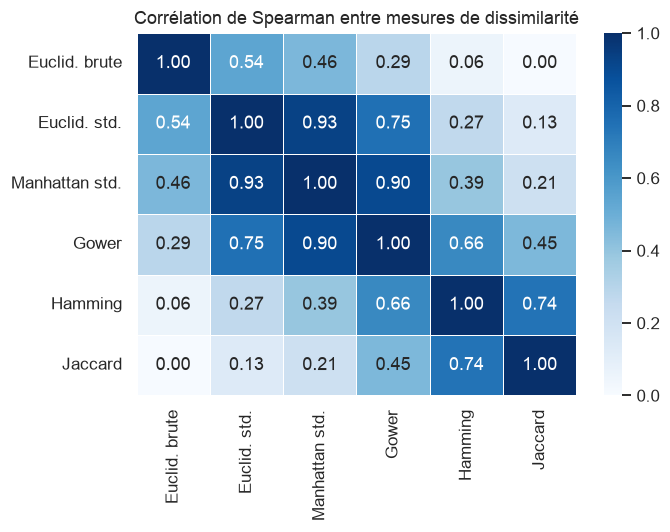

In [10]:
rng = np.random.default_rng(SEED)
sel = rng.choice(len(iu[0]), size=200_000, replace=False)
pairs = (iu[0][sel], iu[1][sel])
dist_tab = pd.DataFrame({
    "Euclid. brute": D_euc_raw[pairs], "Euclid. std.": D_euc[pairs],
    "Manhattan std.": D_man[pairs], "Gower": D_gow[pairs],
    "Hamming": D_ham[pairs], "Jaccard": D_jac[pairs]})
rho = dist_tab.corr(method="spearman")
plt.figure(figsize=(6.5, 5))
sns.heatmap(rho, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, linewidths=.5)
plt.title("Corrélation de Spearman entre mesures de dissimilarité")
plt.tight_layout(); plt.savefig(FIG / "02_correlation_distances.png", bbox_inches="tight"); plt.show()

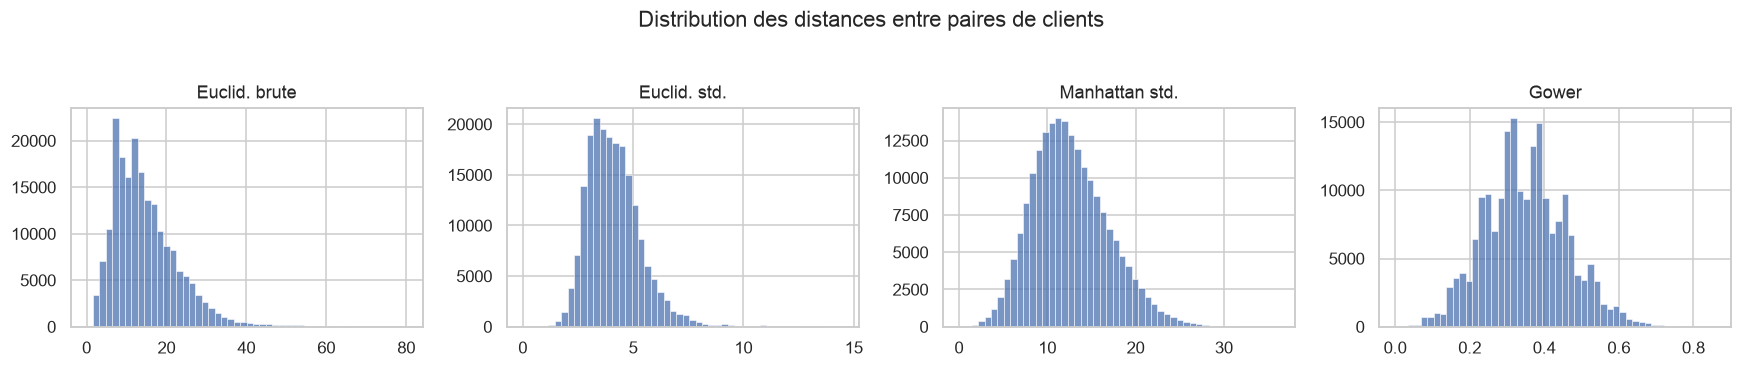

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, col in zip(axes, ["Euclid. brute", "Euclid. std.", "Manhattan std.", "Gower"]):
    sns.histplot(dist_tab[col], bins=50, ax=ax, color="#4C72B0"); ax.set_title(col); ax.set_xlabel(""); ax.set_ylabel("")
plt.suptitle("Distribution des distances entre paires de clients", y=1.04)
plt.tight_layout(); plt.savefig(FIG / "02_distributions_distances.png", bbox_inches="tight"); plt.show()

**Bilan de la partie A — choix et justification des distances**

| Méthode | Distance retenue | Justification |
|---|---|---|
| K-means, GMM, Ward, DBSCAN | Euclidienne sur la représentation (a) **standardisée** | Ces méthodes reposent sur des moyennes et des variances : elles exigent un espace euclidien. La standardisation empêche l'âge de dominer. |
| K-medoids, CAH (liens autres que Ward) | **Gower** | Seule distance qui respecte la nature mixte des données et donne le même poids à chaque variable. |
| K-prototypes | Euclidienne (numériques) + désaccord simple (catégorielles) | Même idée que Gower, intégrée dans l'algorithme. |
| Analyse du bloc binaire | Jaccard pour les « oui » rares, Hamming sinon | Selon que la variable est asymétrique ou symétrique. |

La distance euclidienne brute est très peu corrélée aux autres : elle ne mesure presque que l'écart d'âge. Elle est écartée.

# Partie B — K-means et méthode du coude

K-means cherche $k$ centres qui minimisent l'**inertie intra-classe** $W = \sum_{c}\sum_{x \in C_c} \lVert x - \mu_c\rVert^2$.
L'inertie diminue toujours quand $k$ augmente : on cherche le **coude**, c'est-à-dire le $k$ au-delà duquel ajouter un cluster ne rapporte plus grand-chose.

K-means est rapide : la courbe du coude est tracée sur la **population complète** (41 176 clients).

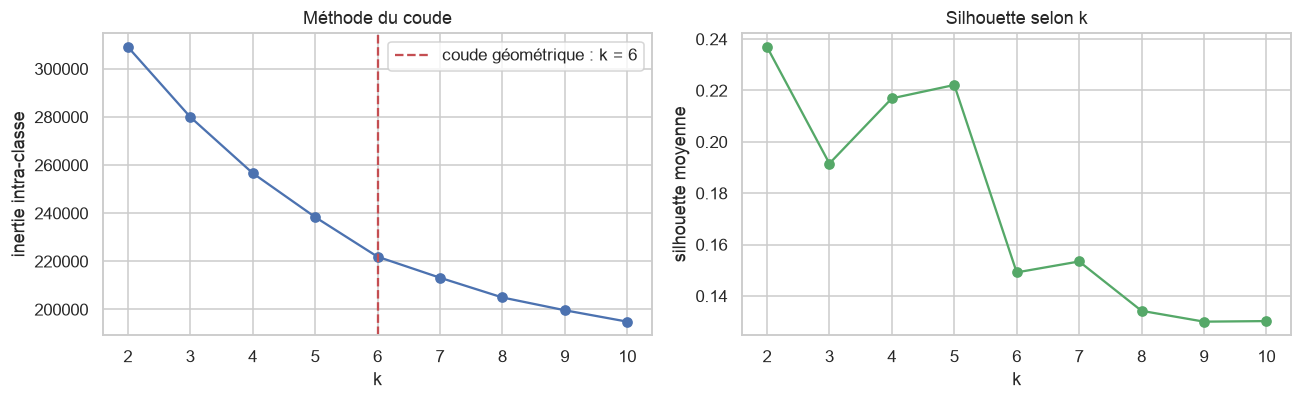

,k,inertie,silhouette,gain d'inertie (%)
0,2,309128.170,0.237,NaN
1,3,279986.774,0.192,9.4
2,4,256651.904,0.217,8.3
3,5,238401.447,0.222,7.1
4,6,221918.648,0.149,6.9
5,7,213186.680,0.153,3.9
6,8,204975.864,0.134,3.9
7,9,199659.909,0.130,2.6
8,10,194925.770,0.130,2.4


In [12]:
ks = list(range(2, 11))
inertia, sil_full = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_a_full)
    inertia.append(km.inertia_)
    sil_full.append(silhouette_score(X_a_full, km.labels_, sample_size=5000, random_state=SEED))
elbow = pd.DataFrame({"k": ks, "inertie": inertia, "silhouette": sil_full})
elbow["gain d'inertie (%)"] = (-100 * elbow["inertie"].pct_change()).round(1)
k_elbow = ks[knee_point(inertia)]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(ks, inertia, "o-"); axes[0].axvline(k_elbow, ls="--", color="#C44E52", label=f"coude géométrique : k = {k_elbow}")
axes[0].set_xlabel("k"); axes[0].set_ylabel("inertie intra-classe"); axes[0].set_title("Méthode du coude"); axes[0].legend()
axes[1].plot(ks, sil_full, "o-", color="#55A868"); axes[1].set_xlabel("k"); axes[1].set_ylabel("silhouette moyenne"); axes[1].set_title("Silhouette selon k")
plt.tight_layout(); plt.savefig(FIG / "02_kmeans_coude.png", bbox_inches="tight"); plt.show()
elbow.round(3)

**Lecture.** La courbe d'inertie décroît régulièrement, sans cassure franche : c'est le signe de clusters qui se chevauchent. Les deux critères ne désignent pas le même $k$ :
- le **coude** : chaque groupe ajouté fait gagner 7 à 9 % d'inertie jusqu'à k = 6, puis moins de 4 % ensuite. Le coude géométrique se situe donc vers **k = 6** ;
- la **silhouette** : elle est maximale pour **k = 2** (0,24), reste correcte jusqu'à k = 5 (environ 0,20), puis chute à partir de k = 6.

→ Le coude donne une borne haute (inutile d'aller au-delà de 6), la silhouette préfère peu de groupes. On garde donc les partitions pour **k = 2 à 6** ; le choix final sera fait au Jour 4 avec tous les indices.

Pour comparer K-means aux méthodes à matrice de distances, on l'ajuste aussi sur l'échantillon de 4 000 clients.

In [13]:
partitions = pd.DataFrame(index=X_a.index)      # toutes les partitions du projet
timing = {}
K_RANGE = range(2, 7)

t0 = time.perf_counter()
for k in K_RANGE:
    partitions[f"kmeans_k{k}"] = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X_a)
timing["K-means"] = (time.perf_counter() - t0) / len(K_RANGE)

# Cohérence échantillon / population pour k = 3
km_full = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(X_a_full)
print(f"ARI entre K-means(population) et K-means(échantillon), k = 3 : "
      f"{adjusted_rand_score(km_full.predict(X_a), partitions['kmeans_k3']):.3f}")

ARI entre K-means(population) et K-means(échantillon), k = 3 : 0.995


# Partie C — K-medoids sur la matrice de Gower

Même principe que K-means, mais le centre de chaque cluster est un **médoïde** : un client réel, celui qui minimise la somme des distances aux autres membres. Deux avantages :
- il fonctionne avec **n'importe quelle matrice de dissimilarité** (ici Gower) ;
- il est plus robuste aux valeurs extrêmes, et le médoïde est un « client type » directement lisible.

> **Note technique.** Le sujet indique `scikit-learn-extra`. Cette bibliothèque n'est plus maintenue et ne s'importe pas avec NumPy ≥ 2. La fonction `kmedoids()` de `src/clustering_utils.py` l'utilise si elle est disponible, et bascule sinon sur une implémentation maison du même algorithme (alternance affectation / mise à jour des médoïdes, initialisation k-medoids++).

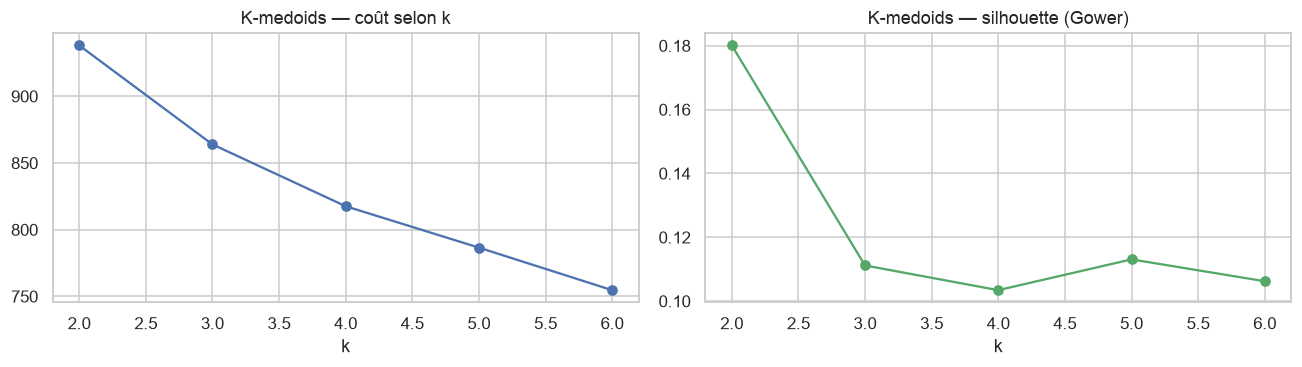

,k,coût (somme des distances aux médoïdes),silhouette (Gower)
0,2,938.155,0.180
1,3,863.937,0.111
2,4,817.589,0.103
3,5,786.567,0.113
4,6,754.688,0.106


In [14]:
t0 = time.perf_counter()
kmed_rows, medoid_idx = [], {}
for k in K_RANGE:
    labels, medoids, cost = kmedoids(D_gow, k, n_init=5, seed=SEED)
    partitions[f"kmedoids_k{k}"] = labels
    medoid_idx[k] = medoids
    kmed_rows.append({"k": k, "coût (somme des distances aux médoïdes)": cost,
                      "silhouette (Gower)": silhouette_score(D_gow, labels, metric="precomputed")})
timing["K-medoids (Gower)"] = (time.perf_counter() - t0) / len(K_RANGE)
kmed = pd.DataFrame(kmed_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(kmed["k"], kmed.iloc[:, 1], "o-"); axes[0].set_title("K-medoids — coût selon k"); axes[0].set_xlabel("k")
axes[1].plot(kmed["k"], kmed.iloc[:, 2], "o-", color="#55A868"); axes[1].set_title("K-medoids — silhouette (Gower)"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.savefig(FIG / "02_kmedoids.png", bbox_inches="tight"); plt.show()
kmed.round(3)

In [15]:
print("Les 3 médoïdes (clients types) pour k = 3 :")
X_mixed.iloc[medoid_idx[3]].assign(effectif=np.bincount(partitions["kmedoids_k3"]))

Les 3 médoïdes (clients types) pour k = 3 :


,age,campaign,previous,cons.price.idx,cons.conf.idx,euribor3m,job,marital,education,default,housing,loan,contact,poutcome,contacted_before,effectif
7546,34,2,0,93.994,-36.4,4.864,admin.,married,university.degree,no,no,no,telephone,nonexistent,no,1336
16085,46,1,0,93.918,-42.7,4.961,blue-collar,married,university.degree,no,yes,no,cellular,nonexistent,no,1593
34325,31,1,0,92.893,-46.2,1.266,admin.,single,high.school,no,yes,no,cellular,nonexistent,no,1071


**Lecture.** La silhouette (calculée en distance de Gower) est la plus élevée pour k = 2 puis se stabilise autour de 0,10 : la structure est **faible** au sens de Gower. Les médoïdes sont instructifs : ils se distinguent surtout par des variables catégorielles (canal de contact, prêt immobilier, statut marital…). Comme Gower donne le même poids à chacune des 15 variables, le contexte économique ne domine plus et K-medoids découpe la clientèle selon d'autres critères que K-means.

# Partie D — K-prototypes sur données mixtes

K-prototypes combine K-means (partie numérique) et K-modes (partie catégorielle). Le coût à minimiser est
$$\sum_{c}\sum_{x\in C_c}\Big(\underbrace{\lVert x^{num}-\mu_c\rVert^2}_{\text{euclidienne}} + \gamma \underbrace{\textstyle\sum_j \mathbb{1}[x^{cat}_j \ne m_{c,j}]}_{\text{désaccords}}\Big)$$
Le prototype d'un cluster est donc une **moyenne** pour les numériques et un **mode** pour les catégorielles ; $\gamma$ règle l'équilibre entre les deux (valeur automatique de `kmodes` : la moitié de l'écart-type moyen des numériques).

Les variables numériques sont standardisées, les catégorielles restent telles quelles.

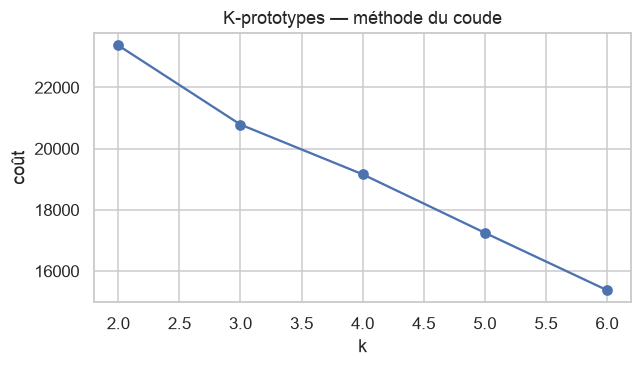

,k,coût,gain (%)
0,2,23376.9,NaN
1,3,20788.2,11.1
2,4,19162.5,7.8
3,5,17252.2,10.0
4,6,15376.1,10.9


In [16]:
X_kp = X_mixed.copy()
X_kp[pp.ACTIVE_NUM] = X_a[pp.ACTIVE_NUM]                     # numériques standardisées
cat_idx = [X_kp.columns.get_loc(c) for c in pp.ACTIVE_CAT]
X_kp_values = X_kp.astype(object).values

t0 = time.perf_counter()
kp_rows, kp_models = [], {}
for k in K_RANGE:
    kp = KPrototypes(n_clusters=k, init="Huang", n_init=3, random_state=SEED)
    partitions[f"kprototypes_k{k}"] = kp.fit_predict(X_kp_values, categorical=cat_idx)
    kp_models[k] = kp
    kp_rows.append({"k": k, "coût": kp.cost_})
timing["K-prototypes"] = (time.perf_counter() - t0) / len(K_RANGE)
kpdf = pd.DataFrame(kp_rows)
kpdf["gain (%)"] = (-100 * kpdf["coût"].pct_change()).round(1)

plt.figure(figsize=(6, 3.5))
plt.plot(kpdf["k"], kpdf["coût"], "o-"); plt.xlabel("k"); plt.ylabel("coût"); plt.title("K-prototypes — méthode du coude")
plt.tight_layout(); plt.savefig(FIG / "02_kprototypes_coude.png", bbox_inches="tight"); plt.show()
kpdf.round(1)

In [17]:
print("Prototypes pour k = 3 (numériques standardisées : 0 = moyenne de la population)")
proto = pd.DataFrame(kp_models[3].cluster_centroids_, columns=pp.ACTIVE_NUM + pp.ACTIVE_CAT)
proto[pp.ACTIVE_NUM] = proto[pp.ACTIVE_NUM].astype(float).round(2)
proto.assign(effectif=np.bincount(partitions["kprototypes_k3"]))

Prototypes pour k = 3 (numériques standardisées : 0 = moyenne de la population)


,age,campaign,previous,cons.price.idx,cons.conf.idx,euribor3m,job,marital,education,default,housing,loan,contact,poutcome,contacted_before,effectif
0,-0.02,-0.18,-0.35,-0.94,-0.53,-0.94,admin.,married,university.degree,no,yes,no,cellular,nonexistent,no,1112
1,0.03,0.11,-0.35,0.61,0.31,0.75,blue-collar,married,university.degree,no,yes,no,telephone,nonexistent,no,2318
2,0.02,-0.29,2.21,-0.85,-0.20,-1.20,admin.,married,university.degree,no,yes,no,cellular,failure,no,570


**Lecture.** Les prototypes sont faciles à lire. Pour k = 3, ils opposent des clients contactés en période de taux élevés (Euribor au-dessus de la moyenne, jamais démarchés auparavant), des clients contactés en période de taux bas, et un petit groupe de clients **déjà démarchés** lors d'une campagne précédente (`previous` très au-dessus de la moyenne).

# Partie E — Modèle de mélange gaussien (GMM)

Le GMM suppose que les données proviennent d'un mélange de $k$ lois normales. Différences avec K-means :
- affectation **probabiliste** (chaque client a une probabilité d'appartenir à chaque groupe) ;
- clusters **elliptiques** de tailles et d'orientations différentes (matrices de covariance).

Le nombre de composantes est choisi par les critères d'information, à **minimiser** :
$\text{BIC} = -2\ln L + q\ln n$ et $\text{AIC} = -2\ln L + 2q$ ($q$ = nombre de paramètres).

Estimer une covariance complète sur 37 colonnes one-hot est instable (colonnes liées entre elles). On ajuste donc le GMM sur les **10 premières composantes principales** (80 % de la variance).

Variance conservée par 10 composantes : 82.4%


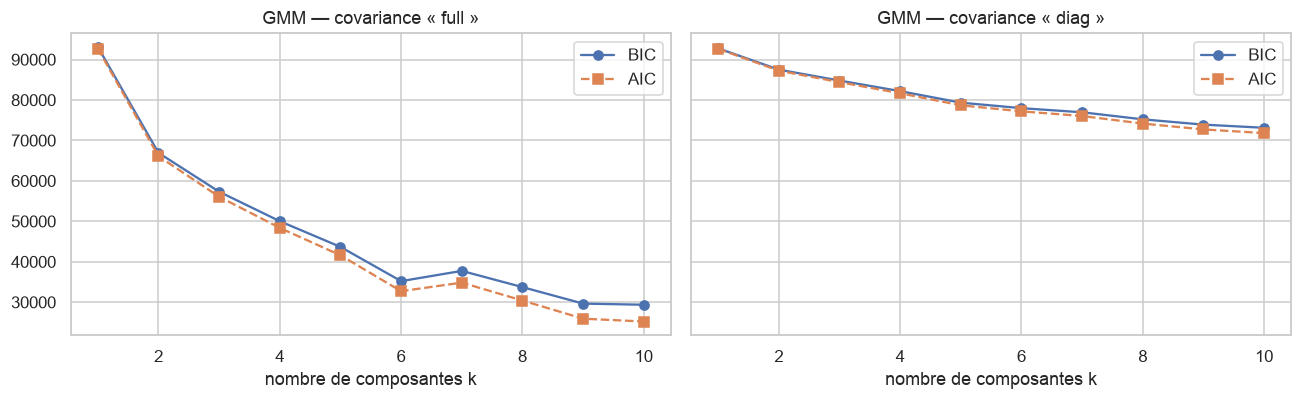

covariance,diag,full
k,,
1,92762.0,93135.0
2,87500.0,66922.0
3,84799.0,57313.0
4,82185.0,50024.0
5,79335.0,43668.0
6,77974.0,35205.0
7,76954.0,37736.0
8,75212.0,33724.0
9,73901.0,29650.0


In [18]:
pca10 = PCA(n_components=10, random_state=SEED).fit(X_a)
Z10 = pca10.transform(X_a)
print(f"Variance conservée par 10 composantes : {pca10.explained_variance_ratio_.sum():.1%}")

t0 = time.perf_counter()
gmm_rows = []
for cov in ["full", "diag"]:
    for k in range(1, 11):
        gm = GaussianMixture(n_components=k, covariance_type=cov, n_init=3, random_state=SEED).fit(Z10)
        gmm_rows.append({"covariance": cov, "k": k, "BIC": gm.bic(Z10), "AIC": gm.aic(Z10)})
        if cov == "full" and k in K_RANGE:
            partitions[f"gmm_k{k}"] = gm.predict(Z10)
timing["GMM"] = (time.perf_counter() - t0) / 20
gmm = pd.DataFrame(gmm_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, cov in zip(axes, ["full", "diag"]):
    sub = gmm[gmm["covariance"] == cov]
    ax.plot(sub["k"], sub["BIC"], "o-", label="BIC"); ax.plot(sub["k"], sub["AIC"], "s--", label="AIC")
    ax.set_title(f"GMM — covariance « {cov} »"); ax.set_xlabel("nombre de composantes k"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "02_gmm_bic_aic.png", bbox_inches="tight"); plt.show()
gmm.pivot(index="k", columns="covariance", values="BIC").round(0)

**Lecture — un résultat à interpréter avec prudence.**
- La covariance **complète** (`full`) donne des BIC nettement plus bas que la covariance diagonale : les variables sont corrélées à l'intérieur des groupes.
- BIC et AIC **continuent de décroître** jusqu'à k = 10 : aucun minimum net n'apparaît. Ce n'est pas la preuve qu'il existe 10 segments. Les données contiennent des indicatrices et des indicateurs économiques qui ne prennent que quelques valeurs : elles sont loin d'être gaussiennes, et le modèle ajoute des composantes pour épouser chaque petit paquet de points. Le BIC ne peut donc pas servir seul à choisir $k$ ici.
- On retient les partitions GMM pour k = 2 à 6 et on les jugera au Jour 4 avec les mêmes indices que les autres méthodes.

# Partie F — Tableau comparatif des méthodes de partitionnement

Pour comparer équitablement, la silhouette est calculée dans **les deux espaces** :
- *silhouette euclidienne* : sur la représentation (a) — espace « naturel » de K-means et GMM ;
- *silhouette Gower* : sur la matrice de Gower — espace « naturel » de K-medoids et K-prototypes.

Rappels : silhouette ∈ [−1, 1], **plus haut = mieux** ; Davies-Bouldin ≥ 0, **plus bas = mieux**.

In [19]:
names = {"kmeans": "K-means", "kmedoids": "K-medoids (Gower)", "kprototypes": "K-prototypes", "gmm": "GMM"}
rows = []
for key, name in names.items():
    for k in [2, 3, 4]:
        lab = partitions[f"{key}_k{k}"].values
        sizes = np.bincount(lab)
        rows.append({"méthode": name, "k": k,
                     "silhouette eucl.": silhouette_score(X_a, lab),
                     "silhouette Gower": silhouette_score(D_gow, lab, metric="precomputed"),
                     "Davies-Bouldin": davies_bouldin_score(X_a, lab),
                     "plus petit cluster (%)": 100 * sizes.min() / n,
                     "tailles": " / ".join(map(str, sorted(sizes, reverse=True)))})
comp = pd.DataFrame(rows)
comp.to_csv(TAB / "02_comparatif_partitionnement.csv", index=False)
comp.style.format({"silhouette eucl.": "{:.3f}", "silhouette Gower": "{:.3f}", "Davies-Bouldin": "{:.2f}",
                   "plus petit cluster (%)": "{:.1f}"}).background_gradient(
    subset=["silhouette eucl.", "silhouette Gower"], cmap="Greens").hide(axis="index")

méthode,k,silhouette eucl.,silhouette Gower,Davies-Bouldin,plus petit cluster (%),tailles
K-means,2,0.237,0.233,1.88,33.8,2650 / 1350
K-means,3,0.186,0.175,1.92,14.2,2326 / 1104 / 570
K-means,4,0.182,0.121,1.84,7.9,2030 / 1085 / 569 / 316
K-medoids (Gower),2,0.111,0.180,2.54,45.5,2182 / 1818
K-medoids (Gower),3,0.039,0.111,3.73,26.8,1593 / 1336 / 1071
K-medoids (Gower),4,0.042,0.103,3.86,21.8,1075 / 1035 / 1018 / 872
K-prototypes,2,0.236,0.232,1.88,33.8,2647 / 1353
K-prototypes,3,0.185,0.175,1.92,14.2,2318 / 1112 / 570
K-prototypes,4,0.126,0.089,2.26,7.6,1519 / 1159 / 1017 / 305
GMM,2,0.235,0.233,1.89,34.6,2616 / 1384


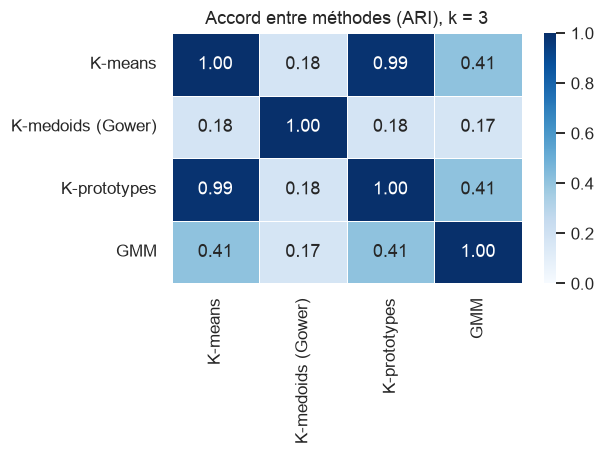

In [20]:
# Les méthodes trouvent-elles les mêmes groupes ? ARI entre partitions (k = 3)
cols3 = [f"{key}_k3" for key in names]
agree = pd.DataFrame([[adjusted_rand_score(partitions[a], partitions[b]) for b in cols3] for a in cols3],
                     index=names.values(), columns=names.values())
plt.figure(figsize=(5.8, 4.3))
sns.heatmap(agree, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, linewidths=.5)
plt.title("Accord entre méthodes (ARI), k = 3")
plt.tight_layout(); plt.savefig(FIG / "02_accord_methodes.png", bbox_inches="tight"); plt.show()

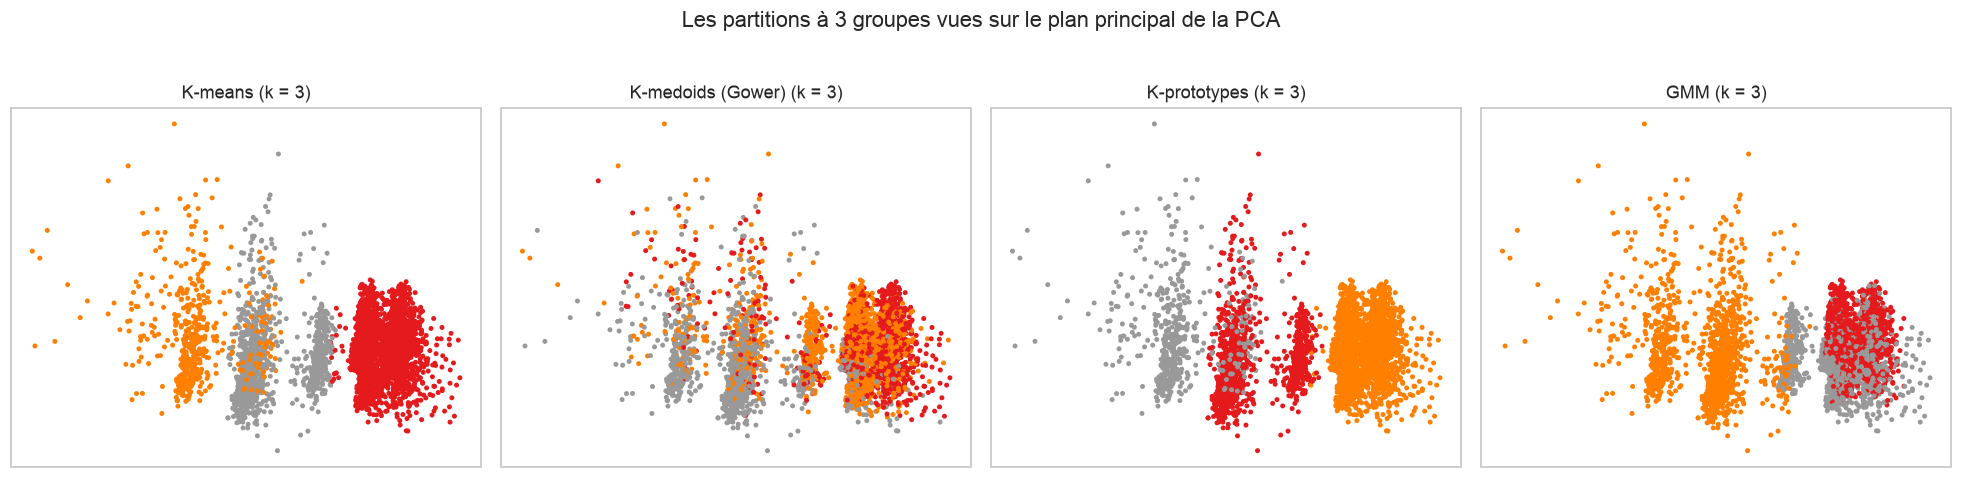

In [21]:
# Visualisation des quatre partitions (k = 3) sur le plan principal de la PCA (Jour 1)
emb = np.load(OUT / "embeddings_sample.npz")
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, (key, name) in zip(axes, names.items()):
    ax.scatter(emb["pca"][:, 0], emb["pca"][:, 1], c=partitions[f"{key}_k3"], s=5, cmap="Set1")
    ax.set_title(f"{name} (k = 3)"); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Les partitions à 3 groupes vues sur le plan principal de la PCA", y=1.03)
plt.tight_layout(); plt.savefig(FIG / "02_partitions_pca.png", bbox_inches="tight"); plt.show()

In [22]:
print("Temps de calcul moyen par ajustement (4 000 clients) :")
print(pd.Series(timing).round(2).astype(str).add(" s").to_string())

Temps de calcul moyen par ajustement (4 000 clients) :
K-means              0.05 s
K-medoids (Gower)    0.51 s
K-prototypes         2.65 s
GMM                  0.12 s


### Synthèse qualitative

| Méthode | Données | Distance | Forme des clusters | Points forts | Limites observées ici |
|---|---|---|---|---|---|
| **K-means** | (a) one-hot standardisé | euclidienne | sphériques, tailles voisines | très rapide, passe à l'échelle (41 000 clients) | sensible à l'initialisation et aux extrêmes ; centres non interprétables sur des indicatrices |
| **K-medoids** | matrice de Gower | Gower | quelconque autour d'un client type | robuste, médoïdes lisibles, respecte les données mixtes | matrice $n^2$ en mémoire ; structure faible (silhouette ≈ 0,1) |
| **K-prototypes** | (b) mixtes | euclidienne + désaccords | sphériques (partie numérique) | natif pour le mixte, prototypes très lisibles | lent ; dépend de $\gamma$ |
| **GMM** | PCA (10 axes) | vraisemblance gaussienne | elliptiques, affectation souple | probabilités d'appartenance | hypothèse gaussienne non vérifiée, BIC sans minimum |

### Bilan du Jour 2
1. **La standardisation est indispensable** : sans elle, l'âge porte presque toute la distance.
2. **Gower** est la distance adaptée aux données mixtes ; elle donne une vision différente de l'euclidienne (accord faible entre K-medoids et les autres méthodes).
3. K-means, K-prototypes et GMM s'accordent presque parfaitement à **k = 2** (ARI de 0,97 à 0,99 : contexte de taux élevés contre taux bas). À k = 3, K-means et K-prototypes restent d'accord (ARI = 0,99) et isolent un troisième groupe de clients déjà démarchés ; le GMM découpe autrement.
4. À ce stade, les meilleurs candidats sont **K-means et K-prototypes avec k = 2 ou 3**. À k = 4, K-prototypes dépend fortement de l'initialisation (deux exécutions dans des environnements différents donnent un ARI de 0,51 entre elles). La décision est reportée au Jour 4.

In [23]:
partitions.to_csv(LAB / "partitions_j2.csv")
print("Partitions enregistrées :", partitions.shape[1], "colonnes ->", LAB / "partitions_j2.csv")

Partitions enregistrées : 20 colonnes -> /Users/NOKHO/Desktop/M1BDA/Semestre2_M1BDA/Apprentissage non suppervisé/Projet/segmentation-bancaire/outputs/labels/partitions_j2.csv
